In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import math as m
from scipy.integrate import solve_ivp

In [25]:
### Parameters ###

DH_A = -45 ## kJ/mol
F_A0 = 1 ## kmol/h
P = 2 ## bar
T0 = 500 ## K
R = 8.314 ## J/mol.K
Cp = 2 ## kJ/kg.K
d_R = 0.03 ## m
l = 3 ## m
Ma = 50 ## kg/kmol


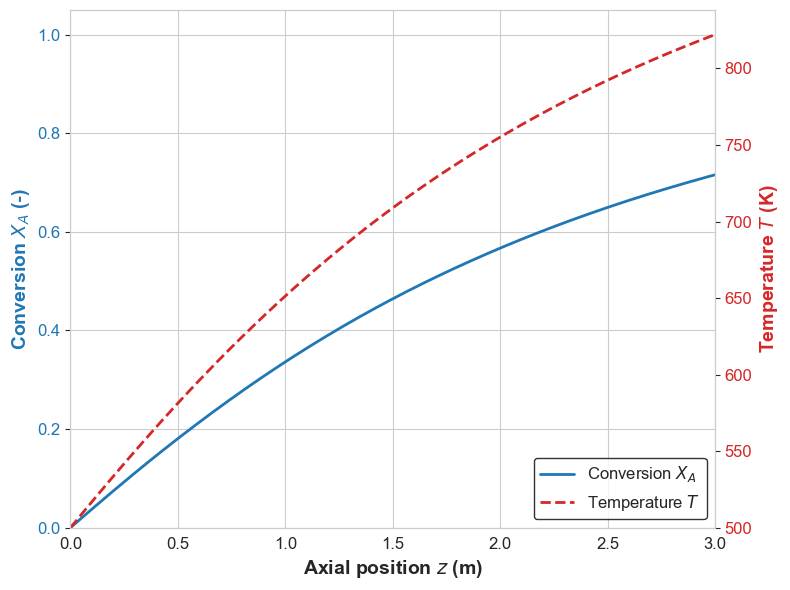

In [ ]:
## 1. Adiabatic reactor 
# Reactor cross-sectional area
Ac = np.pi * (d_R**2) / 4

# Unit conversions for consistency (J, mol, Pa)
P_Pa = P * 1e5             # 2 bar -> 200,000 Pa
F_A0_mol = F_A0 * 1000     # Initial molar flow rate F_A0: 1 kmol/h -> 1000 mol/h
DH_A_J = DH_A * 1000       # -45 kJ/mol -> -45,000 J/mol

# Cp conversion (kJ/kg.K -> J/kg.K) multiplied by molar mass Ma (kg/kmol)
Cp_mol = (Cp * 1000) * Ma/1000  # J/mol.K     

def systeme_pfr(z, y):
    X_A, T_z = y

    k = 2*10**5 * np.exp(-12000/(R*T_z))
    C_A = (P_Pa / (R * T_z)) * ((1 - X_A) / (1 + X_A))

    r_A = k * C_A

    dX_dz = (r_A * Ac) / F_A0_mol
    dT_dz = (r_A * (-DH_A_J) * Ac) / (F_A0_mol * Cp_mol)

    return [dX_dz, dT_dz]

# Numerical integration between z=0 and z=l
sol = solve_ivp(systeme_pfr, [0, l], [0.0, T0], method='RK45', dense_output=True)

# Data retrieval for plotting
z_eval = np.linspace(0, l, 200)
X_out, T_out = sol.sol(z_eval)

# Plotting (single plot with dual Y-axis)
sns.set_style("whitegrid")
fig, ax1 = plt.subplots(figsize=(8, 6))

# Custom font sizes
titre_axe_size = 14
chiffres_axe_size = 12
legende_size = 12

# Primary left axis: Conversion
color1 = 'tab:blue'
line1 = ax1.plot(z_eval, X_out, color=color1, linewidth=2, label='Conversion $X_A$')
ax1.set_xlabel('Axial position $z$ (m)', fontweight='bold', fontsize=titre_axe_size)
ax1.set_ylabel('Conversion $X_A$ (-)', color=color1, fontweight='bold', fontsize=titre_axe_size)
ax1.tick_params(axis='x', labelsize=chiffres_axe_size)
ax1.tick_params(axis='y', labelcolor=color1, labelsize=chiffres_axe_size)
ax1.set_xlim([0, l])
ax1.set_ylim([0, 1.05]) 

# Secondary right axis: Temperature
ax2 = ax1.twinx()  
color2 = 'tab:red'
line2 = ax2.plot(z_eval, T_out, color=color2, linestyle='--', linewidth=2, label='Temperature $T$')
ax2.set_ylabel('Temperature $T$ (K)', color=color2, fontweight='bold', fontsize=titre_axe_size)
ax2.tick_params(axis='y', labelcolor=color2, labelsize=chiffres_axe_size)
ax2.set_ylim(bottom=500)
ax2.grid(False) 

# Legend grouping
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower right', frameon=True, edgecolor='black', fontsize=legende_size)

fig.tight_layout()
plt.show()

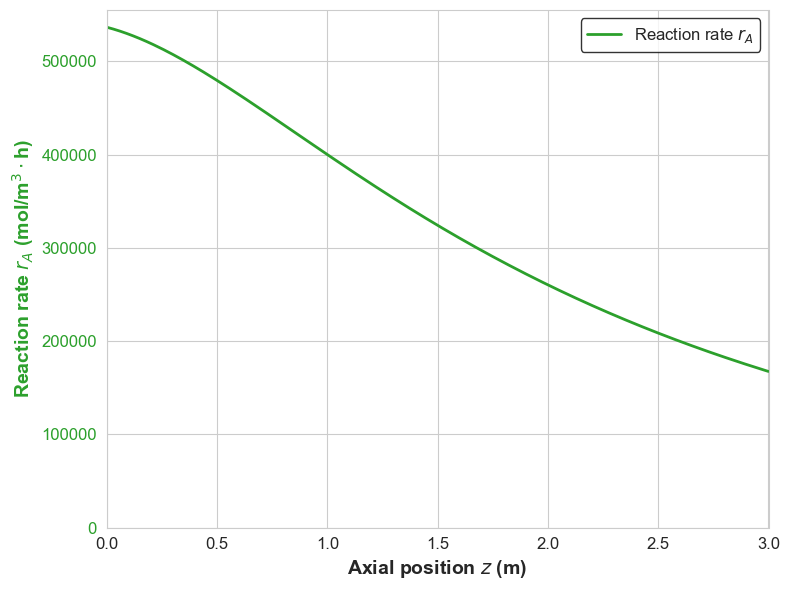

In [27]:
# Évaluation de la vitesse de réaction le long du réacteur
r_A_eval = []
for i in range(len(z_eval)):
    X_i = X_out[i]
    T_i = T_out[i]
    k_i = 2 * 10**5 * np.exp(-12000 / (R * T_i))
    C_A_i = (P_Pa / (R * T_i)) * ((1 - X_i) / (1 + X_i))
    r_A_eval.append(k_i * C_A_i)

# Tracé graphique de r_A en fonction de z
fig, ax = plt.subplots(figsize=(8, 6))

color = 'tab:green'
ax.plot(z_eval, r_A_eval, color=color, linewidth=2, label='Reaction rate $r_A$')
ax.set_xlabel('Axial position $z$ (m)', fontweight='bold', fontsize=titre_axe_size)
ax.set_ylabel('Reaction rate $r_A$ (mol/m$^3\\cdot$h)', color=color, fontweight='bold', fontsize=titre_axe_size)
ax.tick_params(axis='x', labelsize=chiffres_axe_size)
ax.tick_params(axis='y', labelcolor=color, labelsize=chiffres_axe_size)
ax.set_xlim([0, l])
ax.set_ylim(bottom=0)

ax.legend(loc='upper right', frameon=True, edgecolor='black', fontsize=legende_size)

fig.tight_layout()
plt.show()

Required length for 95% conversion : 7.301 m
Exit temperature : 927.5 K


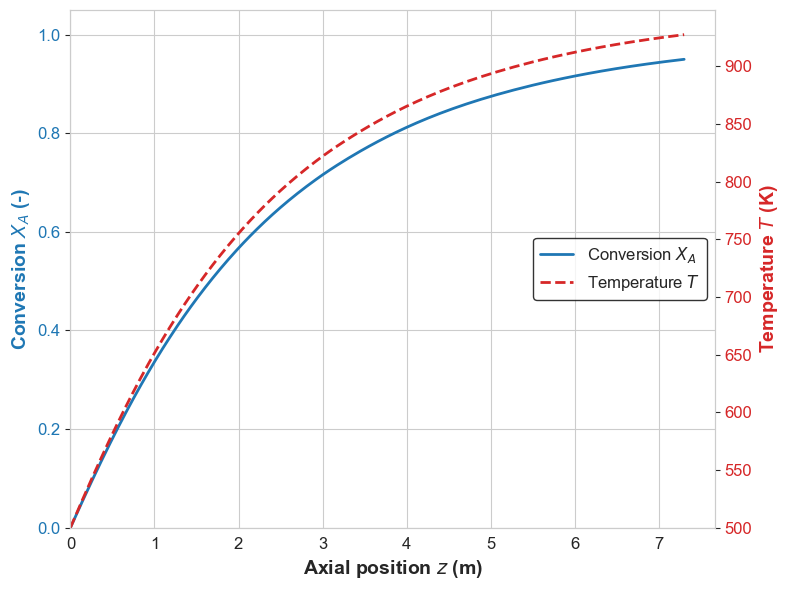

In [28]:
## 1. Adiabatic reactor (Length search for XA = 0.95)
# Area of the reactor cross-section
Ac = np.pi * (d_R**2) / 4

# Unit conversions for consistency (J, mol, Pa)
P_Pa = P * 1e5             
F_A0_mol = F_A0 * 1000     
DH_A_J = DH_A * 1000       

# Cp conversion (kJ/kg.K -> J/kg.K) multiplied by molar mass Ma (kg/kmol = kg/mol / 1000)
Cp_mol = (Cp * 1000) * (Ma / 1000)  # J/mol.K     

# The independent variable is now X_A
def systeme_pfr(X_A, y):
    z, T_z = y

    k = 2*10**5 * np.exp(-12000/(R*T_z))
    C_A = (P_Pa / (R * T_z)) * ((1 - X_A) / (1 + X_A))

    r_A = k * C_A

    dz_dxa = F_A0_mol / (r_A * Ac)
    dT_dxa = -DH_A_J / Cp_mol

    return [dz_dxa, dT_dxa]

# Numerical integration (X_A ranges from 0 to 0.95)
sol = solve_ivp(systeme_pfr, [0, 0.95], [0.0, T0], method='RK45', dense_output=True)

# Data retrieval for plotting
X_eval = np.linspace(0, 0.95, 200)
z_out, T_out = sol.sol(X_eval)

print(f"Required length for 95% conversion : {z_out[-1]:.3f} m")
print(f"Exit temperature : {T_out[-1]:.1f} K")

# Plotting (single plot with dual Y-axis)
sns.set_style("whitegrid") 
fig, ax1 = plt.subplots(figsize=(8, 6))

# Custom font sizes
titre_axe_size = 14
chiffres_axe_size = 12
legende_size = 12

# Primary left axis: Conversion X_A as a function of z_out
color1 = 'tab:blue'
line1 = ax1.plot(z_out, X_eval, color=color1, linewidth=2, label='Conversion $X_A$')
ax1.set_xlabel('Axial position $z$ (m)', fontweight='bold', fontsize=titre_axe_size)
ax1.set_ylabel('Conversion $X_A$ (-)', color=color1, fontweight='bold', fontsize=titre_axe_size)
ax1.tick_params(axis='x', labelsize=chiffres_axe_size)
ax1.tick_params(axis='y', labelcolor=color1, labelsize=chiffres_axe_size)
ax1.set_xlim(left=0)      
ax1.set_ylim([0, 1.05])       

# Secondary right axis: Temperature T as a function of z_out
ax2 = ax1.twinx()  
color2 = 'tab:red'
line2 = ax2.plot(z_out, T_out, color=color2, linestyle='--', linewidth=2, label='Temperature $T$')
ax2.set_ylabel('Temperature $T$ (K)', color=color2, fontweight='bold', fontsize=titre_axe_size)
ax2.tick_params(axis='y', labelcolor=color2, labelsize=chiffres_axe_size)
ax2.set_ylim(bottom=500)
ax2.grid(False) 

# Legend grouping
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', frameon=True, edgecolor='black', fontsize=legende_size)

fig.tight_layout()
plt.show()